In [7]:
# tutorial
from deepface import DeepFace
import matplotlib.pyplot as plt
import cv2

Face Detection and Printing all faces detected in an image

Face 1


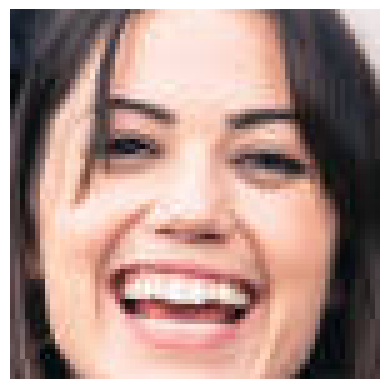

Face 2


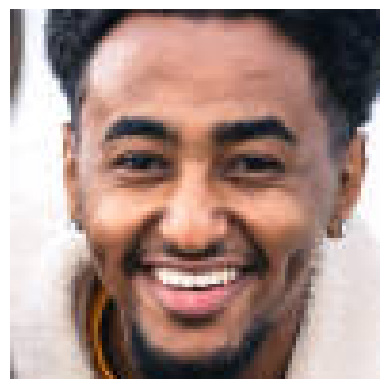

Face 3


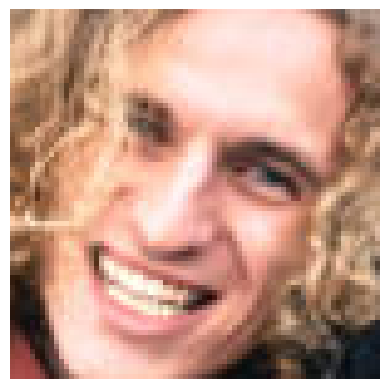

Face 4


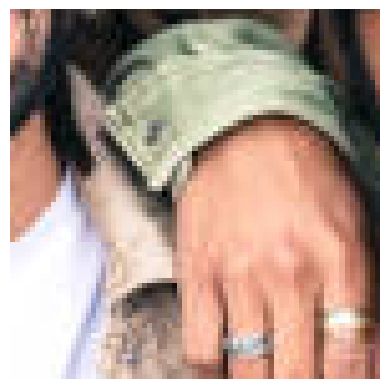

Face 5


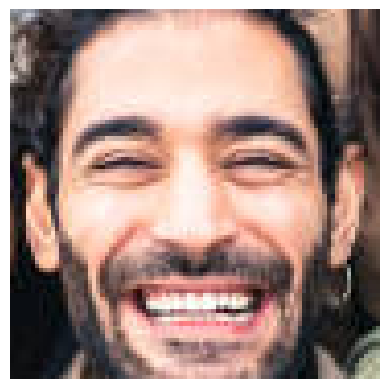

Face 6


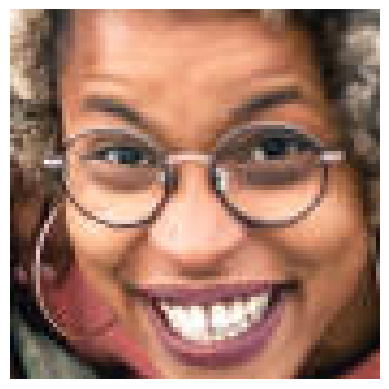

Face 7


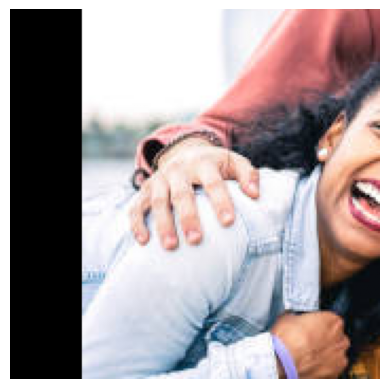

Face 8


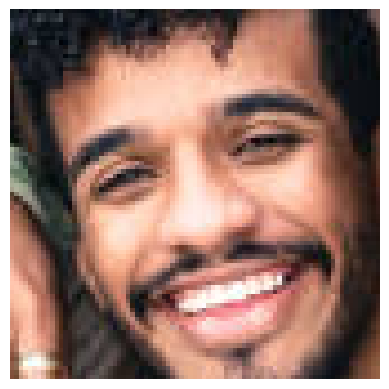

In [8]:
faces = DeepFace.extract_faces("facedb/people.png", detector_backend="opencv")

for i, face in enumerate(faces):
    print(f"Face {i + 1}")
    plt.imshow(face["face"])
    plt.axis("off")
    plt.show()

AT&T Baseline - Read all faces in the dataset and report baseline accuracy. Verified 1716, average overall accuracy 95.33%

In [9]:
import os
from deepface import DeepFace

database_correct = 0
database_total = 0

for i in range(1, 41):
    folder = f"attdb/s{i}"
    images = sorted(os.listdir(folder))

    print(f"\nTesting {folder}")

    correct = 0
    total = 0

    for j in range(len(images)):
        for k in range(j + 1, len(images)):
            img1 = os.path.join(folder, images[j])
            img2 = os.path.join(folder, images[k])

            result = DeepFace.verify(
                img1_path=img1,
                img2_path=img2,
                model_name="Facenet",
                detector_backend="skip"
            )

            total += 1

            if result["verified"]:
                correct += 1

    database_correct += correct
    database_total += total

    print(f"Verified: {correct}/{total}")
    print(f"Accuracy: {correct / total * 100:.2f}%")

print("\n===== OVERALL DATABASE RESULTS =====")
print(f"Verified: {database_correct}/{database_total}")
print(f"Average Accuracy: {database_correct / database_total * 100:.2f}%")


Testing attdb/s1
Verified: 44/45
Accuracy: 97.78%

Testing attdb/s2
Verified: 45/45
Accuracy: 100.00%

Testing attdb/s3
Verified: 45/45
Accuracy: 100.00%

Testing attdb/s4
Verified: 45/45
Accuracy: 100.00%

Testing attdb/s5
Verified: 45/45
Accuracy: 100.00%

Testing attdb/s6
Verified: 44/45
Accuracy: 97.78%

Testing attdb/s7
Verified: 34/45
Accuracy: 75.56%

Testing attdb/s8
Verified: 45/45
Accuracy: 100.00%

Testing attdb/s9
Verified: 45/45
Accuracy: 100.00%

Testing attdb/s10
Verified: 42/45
Accuracy: 93.33%

Testing attdb/s11
Verified: 45/45
Accuracy: 100.00%

Testing attdb/s12
Verified: 45/45
Accuracy: 100.00%

Testing attdb/s13
Verified: 36/45
Accuracy: 80.00%

Testing attdb/s14
Verified: 45/45
Accuracy: 100.00%

Testing attdb/s15
Verified: 45/45
Accuracy: 100.00%

Testing attdb/s16
Verified: 42/45
Accuracy: 93.33%

Testing attdb/s17
Verified: 45/45
Accuracy: 100.00%

Testing attdb/s18
Verified: 45/45
Accuracy: 100.00%

Testing attdb/s19
Verified: 37/45
Accuracy: 82.22%

Testing 

Yale Baseline - Read all faces in the dataset and report baseline accuracy. Verified 705/825, average overall accuracy 85.45%

In [10]:
import os
from deepface import DeepFace

folder = "yaledb"

subjects = {}

database_correct = 0
database_total = 0

# Group images by subject
for filename in os.listdir(folder):
    if filename.startswith("subject"):
        subject = filename.split(".")[0]

        if subject not in subjects:
            subjects[subject] = []

        subjects[subject].append(filename)

# Compare images belonging to each subject
for subject, images in sorted(subjects.items()):
    print(f"\nTesting {subject}")

    correct = 0
    total = 0

    images.sort()

    for j in range(len(images)):
        for k in range(j + 1, len(images)):
            img1 = os.path.join(folder, images[j])
            img2 = os.path.join(folder, images[k])

            result = DeepFace.verify(
                img1_path=img1,
                img2_path=img2,
                model_name="Facenet",
                detector_backend="skip"
            )

            total += 1

            if result["verified"]:
                correct += 1

    database_correct += correct
    database_total += total

    print(f"Verified: {correct}/{total}")
    print(f"Accuracy: {correct / total * 100:.2f}%")

print("\n===== OVERALL DATABASE RESULTS =====")
print(f"Verified: {database_correct}/{database_total}")
print(f"Average Accuracy: {database_correct / database_total * 100:.2f}%")


Testing subject01
Verified: 29/55
Accuracy: 52.73%

Testing subject02
Verified: 55/55
Accuracy: 100.00%

Testing subject03
Verified: 55/55
Accuracy: 100.00%

Testing subject04
Verified: 55/55
Accuracy: 100.00%

Testing subject05
Verified: 49/55
Accuracy: 89.09%

Testing subject06
Verified: 50/55
Accuracy: 90.91%

Testing subject07
Verified: 53/55
Accuracy: 96.36%

Testing subject08
Verified: 50/55
Accuracy: 90.91%

Testing subject09
Verified: 49/55
Accuracy: 89.09%

Testing subject10
Verified: 44/55
Accuracy: 80.00%

Testing subject11
Verified: 35/55
Accuracy: 63.64%

Testing subject12
Verified: 35/55
Accuracy: 63.64%

Testing subject13
Verified: 55/55
Accuracy: 100.00%

Testing subject14
Verified: 51/55
Accuracy: 92.73%

Testing subject15
Verified: 40/55
Accuracy: 72.73%

===== OVERALL DATABASE RESULTS =====
Verified: 705/825
Average Accuracy: 85.45%
